In [2]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pandas_ta as ta
from sklearn.feature_selection import VarianceThreshold
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_squared_error, r2_score
from IPython.display import display

In [30]:
# Define the stock ticker and download historical data
ticker_symbol = "AAPL"

def flatten_yf_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Flattens yfinance multi-level columns if present."""
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = ['_'.join(col).strip() for col in df.columns.values]
    return df

def standardize_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Standardizes column names to lowercase_with_underscores."""
    df.columns = (
        df.columns.str.lower()
        .str.replace(r'[^\w]', '_', regex=True)
        .str.replace(r'_+', '_', regex=True)
    )
    return df

# Download stock data
stock_data_raw = yf.download(ticker_symbol, period="5y", group_by='column')

# Apply column standardization
stock_data = flatten_yf_columns(stock_data_raw.copy()) # Use .copy() to avoid SettingWithCopyWarning
stock_data = standardize_columns(stock_data)

[*********************100%***********************]  1 of 1 completed


In [31]:
stock_data.head()

,close_aapl,high_aapl,low_aapl,open_aapl,volume_aapl
Date,,,,,
2021-09-10,145.301025,151.650686,145.037671,151.182512,140893200
2021-09-13,145.866760,147.690700,145.086460,146.920163,102404300
2021-09-14,144.471970,147.349326,143.291779,146.647058,109296300
2021-09-15,145.359528,145.759433,142.765037,144.901102,83281300
2021-09-16,145.125458,145.301032,143.594133,144.784087,68034100


In [32]:
# Handle missing values (fix FutureWarning by using ffill() and bfill())
stock_data_filled = stock_data.ffill().bfill()
stock_data_filled.dropna(inplace=True)

# Create a working copy and rename columns
df = stock_data_filled.copy()
# Construct rename mapping dynamically in case the ticker symbol changes
rename_map = {}
for col_type in ['close', 'open', 'high', 'low', 'volume']:
    original_col = f'{col_type}_{ticker_symbol.lower()}' # e.g., close_tsla
    if original_col in df.columns:
        rename_map[original_col] = col_type
    elif col_type in df.columns: # Already generic (e.g. if only one ticker was downloaded without group_by)
        rename_map[col_type] = col_type

df.rename(columns=rename_map, inplace=True)

# Verify columns exist after renaming
required_cols = ['open', 'high', 'low', 'close', 'volume']
if not all(col in df.columns for col in required_cols):
    print(f"Warning: Not all required columns ({required_cols}) are present after renaming.")
    print("Available columns:", df.columns)
else:
    print("Columns successfully renamed.")

print("Shape after NaN handling and renaming:", df.shape)

Columns successfully renamed.
Shape after NaN handling and renaming: (1254, 5)


In [20]:
df.tail()

,close,high,low,open,volume
Date,,,,,
2026-09-02,592.849976,600.380005,577.000000,578.789978,16552700
2026-09-03,610.679993,619.460022,604.349976,604.489990,19737100
2026-09-04,616.770020,617.460022,605.270020,612.349976,15966200
2026-09-08,613.479980,624.799988,609.739990,616.210022,18909700
2026-09-09,653.690002,657.859985,638.560120,648.640015,35359694


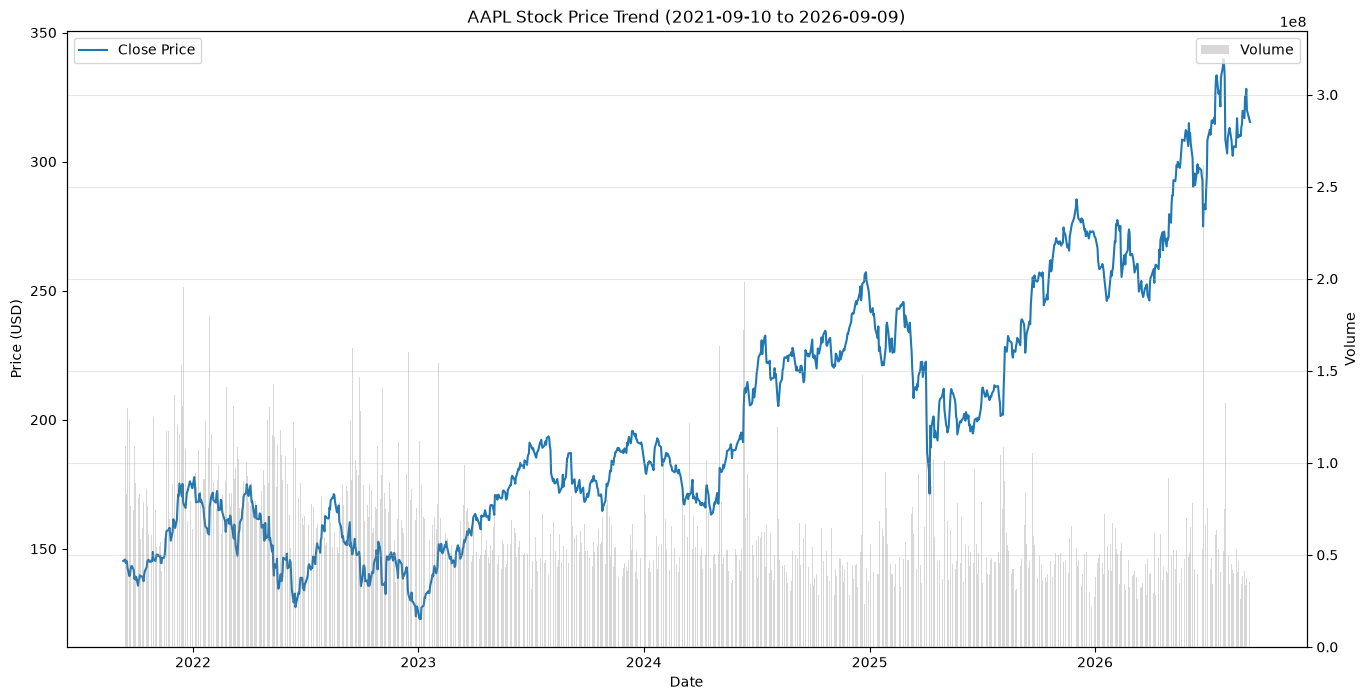

In [33]:
start_date = df.index[0]
end_date = df.index[-1]

plt.figure(figsize=(16, 8))
plt.plot(df.index, df['close'], label='Close Price')

ax1 = plt.gca()
ax2 = ax1.twinx()
ax2.bar(df.index, df['volume'], alpha=0.3, color='gray', label='Volume')
ax2.set_ylabel('Volume')

plt.title(f'{ticker_symbol} Stock Price Trend ({start_date.date()} to {end_date.date()})')
ax1.set_xlabel('Date')
ax1.set_ylabel('Price (USD)')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

plt.grid(True, alpha=0.3)
plt.show()

In [34]:
epsilon = 1e-10 # Small value to avoid division by zero

# 1. Moving Averages
df['SMA_10'] = ta.sma(df['close'], length=10)
df['SMA_50'] = ta.sma(df['close'], length=50)

# 2. Price and MA Ratios
df['Price_vs_SMA50'] = df['close'] / (df['SMA_50'] + epsilon) - 1
df['SMA10_vs_SMA50'] = df['SMA_10'] / (df['SMA_50'] + epsilon) - 1

# 3. MACD (Moving Average Convergence Divergence)
# pandas_ta can create columns like MACD_12_26_9, MACDh_12_26_9, MACDs_12_26_9
macd_df = ta.macd(df['close'], fast=12, slow=26, signal=9)
hist_col_name = next((col for col in macd_df.columns if col.startswith('MACDh')), None)
if hist_col_name and hist_col_name in macd_df.columns:
    df['MACD_Hist'] = macd_df[hist_col_name]
else:
    print(f"Warning: MACD Histogram column (expected to start with 'MACDh') not found. Setting to NaN.")
    df['MACD_Hist'] = np.nan

# 4. ADX (Average Directional Index)
# pandas_ta can create ADX_14, DMP_14, DMN_14
adx_df = ta.adx(df['high'], df['low'], df['close'], length=14)
adx_col_name = next((col for col in adx_df.columns if col.startswith('ADX_')), None)
if adx_col_name and adx_col_name in adx_df.columns:
    df['ADX_14'] = adx_df[adx_col_name]
else:
    print(f"Warning: ADX column (expected to start with 'ADX_') not found. Setting to NaN.")
    df['ADX_14'] = np.nan

# 5. RSI (Relative Strength Index)
df['RSI_14'] = ta.rsi(df['close'], length=14)

# 6. ROC (Rate of Change)
df['ROC_10'] = ta.roc(df['close'], length=10)

# 7. ATR (Average True Range)
df['ATR_14'] = ta.atr(df['high'], df['low'], df['close'], length=14)

# 8. Normalized ATR (ATR as a percentage of close price)
df['ATR_Norm'] = df['ATR_14'] / (df['close'] + epsilon)

# 9. Bollinger Bands
# pandas_ta creates BBL_20_2.0, BBM_20_2.0, BBU_20_2.0, BBB_20_2.0 (Bandwidth), BBP_20_2.0 (%B)
bbands_df = ta.bbands(df['close'], length=20, std=2)
bbw_col_name = next((col for col in bbands_df.columns if col.startswith('BBB_')), None) # Bollinger Bandwidth
if bbw_col_name and bbw_col_name in bbands_df.columns:
    df['BB_Width'] = bbands_df[bbw_col_name]
else: # Manual calculation as fallback for bandwidth if specific column not found
    print(f"Warning: Bollinger Bandwidth column (expected 'BBB_') not found. Attempting manual calculation.")
    upper_col = next((col for col in bbands_df.columns if col.startswith('BBU_')), None)
    lower_col = next((col for col in bbands_df.columns if col.startswith('BBL_')), None)
    middle_col = next((col for col in bbands_df.columns if col.startswith('BBM_')), None)
    if upper_col and lower_col and middle_col and \
       all(c in bbands_df.columns for c in [upper_col, lower_col, middle_col]):
        df['BB_Width'] = (bbands_df[upper_col] - bbands_df[lower_col]) / (bbands_df[middle_col] + epsilon)
    else:
        df['BB_Width'] = np.nan
        print("Manual BB_Width calculation failed due to missing band columns.")


bbp_col_name = next((col for col in bbands_df.columns if col.startswith('BBP_')), None) # Bollinger %B
if bbp_col_name and bbp_col_name in bbands_df.columns:
    df['BB_PctB'] = bbands_df[bbp_col_name]
else:
    print(f"Warning: Bollinger %B column (expected 'BBP_') not found. Setting to NaN.")
    df['BB_PctB'] = np.nan

# 10. Volume Moving Average
df['VOLSMA_20'] = ta.sma(df['volume'], length=20)

# 11. Relative Volume (Volume vs its SMA)
df['Volume_vs_SMA20'] = df['volume'] / (df['VOLSMA_20'] + epsilon) - 1

print(f"Technical indicator calculation complete.")

# Drop rows with NaN values that were introduced by indicators with lookback periods
df.dropna(inplace=True)
print("Shape after feature engineering & NaN drop:", df.shape)
# Split columns into chunks and display each chunk
def show_in_chunks(df, chunk_size=6):
    cols = df.columns.tolist()
    for i in range(0, len(cols), chunk_size):
        print(f"Columns {i+1} to {min(i+chunk_size, len(cols))}:")
        display(df[cols[i:i+chunk_size]].head())
        print('-'*50)

show_in_chunks(df)

Technical indicator calculation complete.
Shape after feature engineering & NaN drop: (1205, 19)
Columns 1 to 6:


,close,high,low,open,volume,SMA_10
Date,,,,,,
2021-11-18,154.206573,154.988012,149.498431,150.143119,137827700,147.561440
2021-11-19,156.824402,157.283497,152.897683,153.991688,117305600,148.466930
2021-11-22,157.283493,161.854885,157.263953,157.928166,117467900,149.500378
2021-11-23,157.664413,158.045363,155.368940,157.381135,96041900,150.535783
2021-11-24,158.182114,158.377470,155.935483,157.019726,69463600,151.905249


--------------------------------------------------
Columns 7 to 12:


,SMA_50,Price_vs_SMA50,SMA10_vs_SMA50,MACD_Hist,ADX_14,RSI_14
Date,,,,,,
2021-11-18,143.559899,0.074162,0.027874,0.487616,23.176908,72.475999
2021-11-19,143.790366,0.090646,0.032523,0.856157,25.297627,75.907869
2021-11-22,144.018701,0.092105,0.038062,1.058630,27.957740,76.462148
2021-11-23,144.282550,0.092748,0.043340,1.138999,29.453501,76.936284
2021-11-24,144.539001,0.094391,0.050964,1.144756,30.899335,77.596787


--------------------------------------------------
Columns 13 to 18:


,ROC_10,ATR_14,ATR_Norm,BB_Width,BB_PctB,VOLSMA_20
Date,,,,,,
2021-11-18,4.729983,2.722055,0.017652,6.113922,1.313595,70130865.0
2021-11-19,6.127720,2.840895,0.018115,8.435977,1.250285,73051975.0
2021-11-22,7.032704,2.997294,0.019057,10.103379,1.113426,76389340.0
2021-11-23,7.028731,2.974375,0.018865,11.445436,1.026372,78146765.0
2021-11-24,9.478094,2.936347,0.018563,12.485660,0.973329,78815200.0


--------------------------------------------------
Columns 19 to 19:


,Volume_vs_SMA20
Date,
2021-11-18,0.965293
2021-11-19,0.605783
2021-11-22,0.537753
2021-11-23,0.228994
2021-11-24,-0.118652


--------------------------------------------------


In [35]:
# List of all engineered features
features_all = ['SMA_10', 'SMA_50', 'Price_vs_SMA50', 'SMA10_vs_SMA50',
                'MACD_Hist', 'ADX_14', 'RSI_14', 'ROC_10', 'ATR_14', 'ATR_Norm',
                'BB_Width', 'BB_PctB', 'VOLSMA_20', 'Volume_vs_SMA20']

# Filter out features that might be all NaN if calculation failed
df_factors = df[[f for f in features_all if f in df.columns and not df[f].isnull().all()]].copy()


# Initialize VarianceThreshold (threshold=0.0 removes constant features)
selector = VarianceThreshold(threshold=0.0)
selector.fit(df_factors)

# Get the mask of features to keep and their names
kept_mask = selector.get_support()
kept_columns = df_factors.columns[kept_mask].tolist()
removed_columns = df_factors.columns[~kept_mask].tolist()

print("\n--- Variance Thresholding Results (threshold=0.0) ---")
if removed_columns:
    print(f"Removed features ({len(removed_columns)}): {removed_columns}")
else:
    print("No features were removed by variance thresholding.")
print(f"Kept features ({len(kept_columns)}): {kept_columns}")


--- Variance Thresholding Results (threshold=0.0) ---
No features were removed by variance thresholding.
Kept features (14): ['SMA_10', 'SMA_50', 'Price_vs_SMA50', 'SMA10_vs_SMA50', 'MACD_Hist', 'ADX_14', 'RSI_14', 'ROC_10', 'ATR_14', 'ATR_Norm', 'BB_Width', 'BB_PctB', 'VOLSMA_20', 'Volume_vs_SMA20']


In [36]:
df['future_ret_5d'] = df['close'].shift(-5) / df['close'] - 1
df.dropna(inplace=True) # Drop rows where future return cannot be calculated (last 5 rows)
print("Shape after defining target variable & NaN drop:", df.shape)
show_in_chunks(df)

Shape after defining target variable & NaN drop: (1200, 20)
Columns 1 to 6:


,close,high,low,open,volume,SMA_10
Date,,,,,,
2021-11-18,154.206573,154.988012,149.498431,150.143119,137827700,147.561440
2021-11-19,156.824402,157.283497,152.897683,153.991688,117305600,148.466930
2021-11-22,157.283493,161.854885,157.263953,157.928166,117467900,149.500378
2021-11-23,157.664413,158.045363,155.368940,157.381135,96041900,150.535783
2021-11-24,158.182114,158.377470,155.935483,157.019726,69463600,151.905249


--------------------------------------------------
Columns 7 to 12:


,SMA_50,Price_vs_SMA50,SMA10_vs_SMA50,MACD_Hist,ADX_14,RSI_14
Date,,,,,,
2021-11-18,143.559899,0.074162,0.027874,0.487616,23.176908,72.475999
2021-11-19,143.790366,0.090646,0.032523,0.856157,25.297627,75.907869
2021-11-22,144.018701,0.092105,0.038062,1.058630,27.957740,76.462148
2021-11-23,144.282550,0.092748,0.043340,1.138999,29.453501,76.936284
2021-11-24,144.539001,0.094391,0.050964,1.144756,30.899335,77.596787


--------------------------------------------------
Columns 13 to 18:


,ROC_10,ATR_14,ATR_Norm,BB_Width,BB_PctB,VOLSMA_20
Date,,,,,,
2021-11-18,4.729983,2.722055,0.017652,6.113922,1.313595,70130865.0
2021-11-19,6.127720,2.840895,0.018115,8.435977,1.250285,73051975.0
2021-11-22,7.032704,2.997294,0.019057,10.103379,1.113426,76389340.0
2021-11-23,7.028731,2.974375,0.018865,11.445436,1.026372,78146765.0
2021-11-24,9.478094,2.936347,0.018563,12.485660,0.973329,78815200.0


--------------------------------------------------
Columns 19 to 20:


,Volume_vs_SMA20,future_ret_5d
Date,,
2021-11-18,0.965293,-0.006714
2021-11-19,0.605783,-0.001931
2021-11-22,0.537753,0.026580
2021-11-23,0.228994,0.020817
2021-11-24,-0.118652,0.011239


--------------------------------------------------


Dataset splitting complete.
X_train shape: (720, 14)
X_val shape: (240, 14)
X_test shape: (240, 14)
y_train shape: (720,)
y_val shape: (240,)
y_test shape: (240,)

Training set range: 2021-11-18 -> 2024-10-01
Validation set range: 2024-10-02 -> 2025-09-17
Test set range: 2025-09-18 -> 2026-09-01

Number of samples in training set: 720
Number of samples in validation set: 240
Number of samples in test set: 240


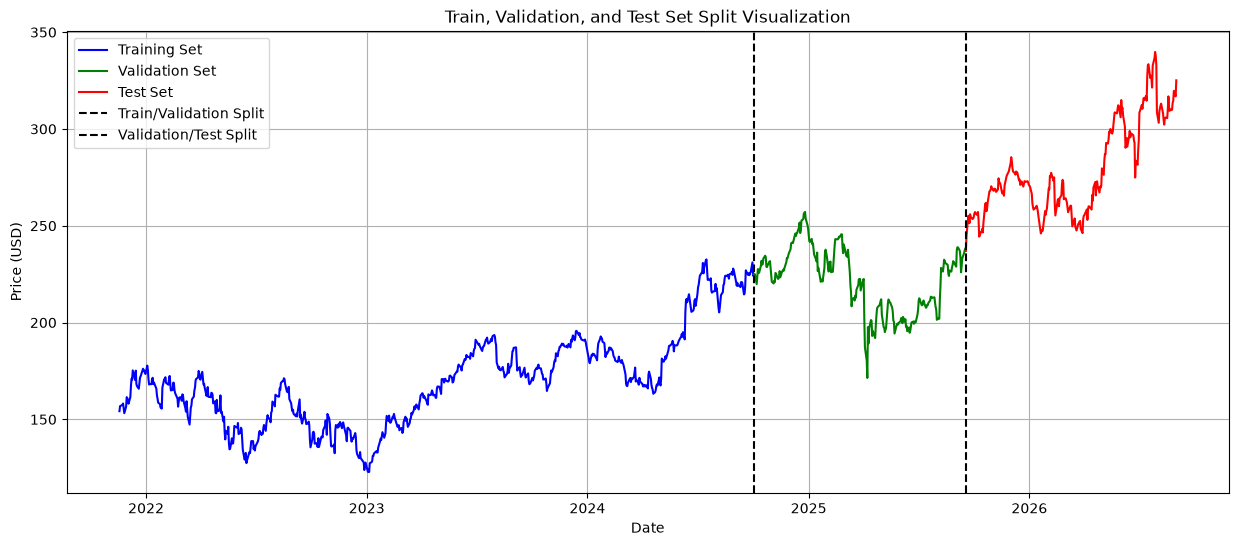

In [37]:
def split_data_sequential(data: pd.DataFrame, train_ratio: float, val_ratio: float, test_ratio: float):
    """Splits data sequentially into train, validation, and test sets."""
    assert abs(train_ratio + val_ratio + test_ratio - 1.0) < 1e-6, "Ratios must sum to 1"
    n = len(data)
    train_end = int(n * train_ratio)
    val_end = train_end + int(n * val_ratio)

    train_data = data.iloc[:train_end]
    val_data = data.iloc[train_end:val_end]
    test_data = data.iloc[val_end:]

    return train_data, val_data, test_data

train_data, val_data, test_data = split_data_sequential(df, train_ratio=0.6, val_ratio=0.2, test_ratio=0.2)
print("Dataset splitting complete.")

# Prepare feature matrices (X) and target vectors (y)
features_for_model = kept_columns # Use features selected by VarianceThreshold
X_train = train_data[features_for_model].values
y_train = train_data['future_ret_5d'].values

X_val = val_data[features_for_model].values
y_val = val_data['future_ret_5d'].values

X_test = test_data[features_for_model].values
y_test = test_data['future_ret_5d'].values

# Print shapes to verify
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_val shape:", y_val.shape)
print("y_test shape:", y_test.shape)

# Display date ranges and sample counts for each set
print("\nTraining set range:", train_data.index.min().date(), "->", train_data.index.max().date())
print("Validation set range:", val_data.index.min().date(), "->", val_data.index.max().date())
print("Test set range:", test_data.index.min().date(), "->", test_data.index.max().date())
print("\nNumber of samples in training set:", len(train_data))
print("Number of samples in validation set:", len(val_data))
print("Number of samples in test set:", len(test_data))

# Visualize the data splits
split_idx_1 = len(train_data)
split_idx_2 = len(train_data) + len(val_data)
split_date_1 = df.index[split_idx_1]
split_date_2 = df.index[split_idx_2]

plt.figure(figsize=(15, 6))
plt.plot(train_data.index, train_data['close'], label='Training Set', color='blue')
plt.plot(val_data.index, val_data['close'], label='Validation Set', color='green')
plt.plot(test_data.index, test_data['close'], label='Test Set', color='red')
plt.axvline(split_date_1, color='black', linestyle='--', label='Train/Validation Split')
plt.axvline(split_date_2, color='black', linestyle='--', label='Validation/Test Split')
plt.title('Train, Validation, and Test Set Split Visualization')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid(True)
plt.show()

In [38]:
# Define TimeSeriesSplit for cross-validation
tscv = TimeSeriesSplit(n_splits=3) # Use more splits for robust tuning if data allows

# Define the Decision Tree Regressor model
base_model = DecisionTreeRegressor(random_state=42)

# Define the hyperparameter grid to search
param_grid = {
    'max_depth': [None, 5, 10, 15], # Reduced 20 to 15 for potentially faster tuning
    'min_samples_split': [2, 5, 10, 20], # Added 20
    'min_samples_leaf': [1, 2, 4, 8], # Added 8
    'max_features': [None, 0.5, 'sqrt', 'log2'] # Replaced 0.3 and 1.0 with 0.5
}

# Setup GridSearchCV
grid_search = GridSearchCV(
    estimator=base_model,
    param_grid=param_grid,
    scoring='neg_mean_squared_error', # Lower MSE is better, so we use negative MSE
    cv=tscv,                          # Use TimeSeriesSplit for cross-validation
    n_jobs=-1,                        # Use all available CPU cores
    verbose=1                         # Show progress
)

# Fit GridSearchCV to find the best model (trains on X_train, y_train)
grid_search.fit(X_train, y_train)

# Get the best hyperparameters and the best model
print("Best Hyperparameters (found using TimeSeriesSplit):", grid_search.best_params_)
best_model = grid_search.best_estimator_

Fitting 3 folds for each of 256 candidates, totalling 768 fits
Best Hyperparameters (found using TimeSeriesSplit): {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 8, 'min_samples_split': 2}


In [28]:
# Predictions on training and validation sets
y_pred_train = best_model.predict(X_train)
y_pred_val = best_model.predict(X_val)

# Calculate metrics
train_mse = mean_squared_error(y_train, y_pred_train)
val_mse = mean_squared_error(y_val, y_pred_val)
train_r2 = r2_score(y_train, y_pred_train)
val_r2 = r2_score(y_val, y_pred_val)

print("\n==== Training Set Performance ====")
print(f"MSE: {train_mse:.6f}")
print(f"R2 Score: {train_r2:.4f}")

print("\n==== Validation Set Performance ====")
print(f"MSE: {val_mse:.6f}")
print(f"R2 Score: {val_r2:.4f}")


# Feature Importances
# Display feature importances from the best model
features = features_for_model  # Use the features selected by VarianceThreshold
feature_importances = best_model.feature_importances_  
for f, imp in zip(features, feature_importances):  
    print(f"Feature: {f}, Importance: {imp:.4f}")  

# Sort and display feature importances
sorted_idx = np.argsort(feature_importances)[::-1]  
print("\nSorted Feature Importances:")  
for idx in sorted_idx:  
    print(f"{features[idx]} -> {feature_importances[idx]:.4f}")

# Make predictions on the test set
y_pred_test = best_model.predict(X_test)


==== Training Set Performance ====
MSE: 0.002706
R2 Score: 0.4230

==== Validation Set Performance ====
MSE: 0.004911
R2 Score: -1.1936
Feature: SMA_10, Importance: 0.2824
Feature: SMA_50, Importance: 0.0000
Feature: Price_vs_SMA50, Importance: 0.0880
Feature: SMA10_vs_SMA50, Importance: 0.2675
Feature: MACD_Hist, Importance: 0.0121
Feature: ADX_14, Importance: 0.1191
Feature: RSI_14, Importance: 0.0000
Feature: ROC_10, Importance: 0.0004
Feature: ATR_14, Importance: 0.1193
Feature: ATR_Norm, Importance: 0.0182
Feature: BB_Width, Importance: 0.0532
Feature: BB_PctB, Importance: 0.0271
Feature: VOLSMA_20, Importance: 0.0000
Feature: Volume_vs_SMA20, Importance: 0.0129

Sorted Feature Importances:
SMA_10 -> 0.2824
SMA10_vs_SMA50 -> 0.2675
ATR_14 -> 0.1193
ADX_14 -> 0.1191
Price_vs_SMA50 -> 0.0880
BB_Width -> 0.0532
BB_PctB -> 0.0271
ATR_Norm -> 0.0182
Volume_vs_SMA20 -> 0.0129
MACD_Hist -> 0.0121
ROC_10 -> 0.0004
VOLSMA_20 -> 0.0000
RSI_14 -> 0.0000
SMA_50 -> 0.0000


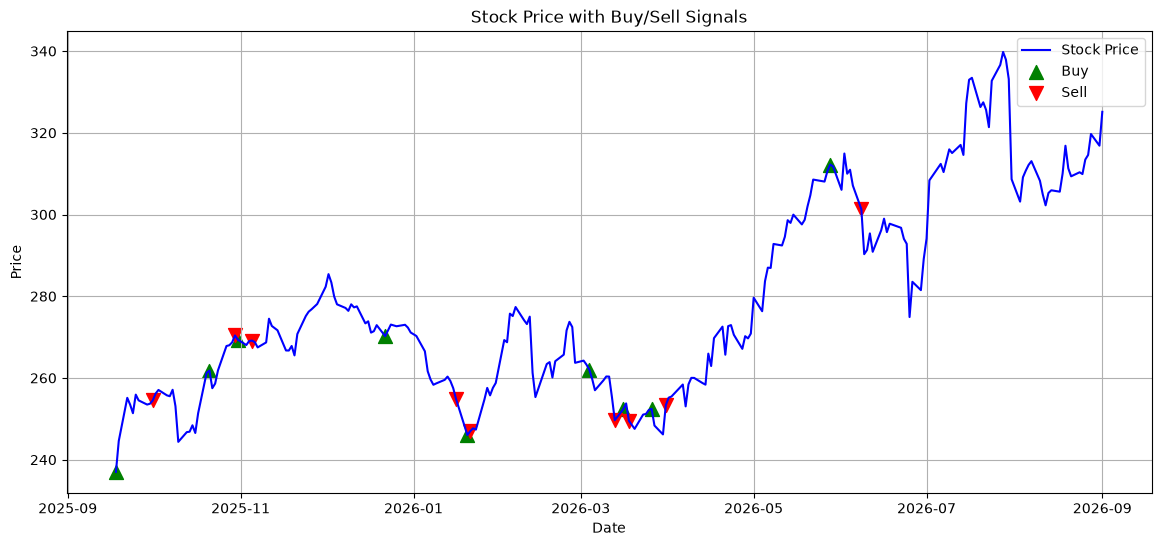

Initial Capital: $1,000,000.00
Final Portfolio Value: $939,774.44
Total Return: -6.02%
Annualized Return: -6.31%
Annualized Volatility: 10.26%
Sharpe Ratio: -0.81
Maximum Drawdown: 15.49%

Trade Log:
      date action      price  shares   cash_change
2025-09-18    BUY 237.004517    4215 -9.999730e+05
2025-10-01   SELL 254.509842    4215  1.071686e+06
2025-10-21    BUY 261.802887    4089 -1.071583e+06
2025-10-30   SELL 270.401154    4089  1.104565e+06
2025-10-31    BUY 269.374908    4096 -1.104463e+06
2025-11-05   SELL 269.145782    4096  1.101319e+06
2025-12-22    BUY 270.234436    4072 -1.101495e+06
2026-01-16   SELL 254.836334    4072  1.036656e+06
2026-01-20    BUY 246.030319    4209 -1.036577e+06
2026-01-21   SELL 246.977737    4209  1.038490e+06
2026-03-04    BUY 262.052338    3959 -1.038503e+06
2026-03-13   SELL 249.674438    3959  9.874726e+05
2026-03-16    BUY 252.369644    3909 -9.874995e+05
2026-03-18   SELL 249.494766    3909  9.742998e+05
2026-03-26    BUY 252.439514    385

In [39]:
dates = test_data.index
prices = test_data['close'].values

# Parameters
initial_capital = 1_000_000  # starting cash
fee_rate = 0.001             # 0.1% per trade
threshold = 0.0              # signal threshold (set to zero)

# Initialize
cash = initial_capital
stock_holding = 0
portfolio_values = []
trade_log = []

for i in range(len(y_pred_test)):
    date = dates[i]
    price = prices[i]
    pred = y_pred_test[i]

    current_position_value = stock_holding * price
    current_total_value = cash + current_position_value

    # Decision: BUY if pred > threshold and not already in; SELL if pred <= threshold and holding
    if pred > threshold and stock_holding == 0:
        # Buy as much as possible
        num_shares = int(cash / (price * (1 + fee_rate)))
        if num_shares > 0:
            cost = num_shares * price * (1 + fee_rate)
            cash -= cost
            stock_holding = num_shares
            trade_log.append({
                'date': date,
                'action': 'BUY',
                'price': price,
                'shares': num_shares,
                'cash_change': -cost
            })

    elif pred <= threshold and stock_holding > 0:
        # Sell all
        proceeds = stock_holding * price * (1 - fee_rate)
        cash += proceeds
        trade_log.append({
            'date': date,
            'action': 'SELL',
            'price': price,
            'shares': stock_holding,
            'cash_change': proceeds
        })
        stock_holding = 0

    # Update portfolio value
    portfolio_value = cash + stock_holding * price
    portfolio_values.append(portfolio_value)

# Final portfolio value (after loop)
final_portfolio_value = cash + stock_holding * prices[-1]

# Create portfolio series
portfolio_series = pd.Series(portfolio_values, index=dates)
returns = portfolio_series.pct_change().fillna(0)
cumulative_returns = (1 + returns).cumprod()

# Calculate performance metrics
total_return = (final_portfolio_value / initial_capital) - 1
annual_return = (final_portfolio_value / initial_capital) ** (252 / len(portfolio_series)) - 1
volatility = returns.std() * np.sqrt(252)
sharpe_ratio = (annual_return - 0.02) / (volatility + 1e-10)
drawdown_series = portfolio_series.cummax() - portfolio_series
max_drawdown = (drawdown_series / portfolio_series.cummax()).max()

# Plot price chart with buy/sell markers
plt.figure(figsize=(14, 6))
plt.plot(dates, prices, label='Stock Price', color='blue')

# Mark buy and sell points
buy_dates = [t['date'] for t in trade_log if t['action'] == 'BUY']
buy_prices = [t['price'] for t in trade_log if t['action'] == 'BUY']
sell_dates = [t['date'] for t in trade_log if t['action'] == 'SELL']
sell_prices = [t['price'] for t in trade_log if t['action'] == 'SELL']

plt.scatter(buy_dates, buy_prices, marker='^', color='green', label='Buy', s=100)
plt.scatter(sell_dates, sell_prices, marker='v', color='red', label='Sell', s=100)

plt.title('Stock Price with Buy/Sell Signals')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.show()

# Print summary
print(f"Initial Capital: ${initial_capital:,.2f}")
print(f"Final Portfolio Value: ${final_portfolio_value:,.2f}")
print(f"Total Return: {total_return:.2%}")
print(f"Annualized Return: {annual_return:.2%}")
print(f"Annualized Volatility: {volatility:.2%}")
print(f"Sharpe Ratio: {sharpe_ratio:.2f}")
print(f"Maximum Drawdown: {max_drawdown:.2%}")

# Print detailed trade log
trade_df = pd.DataFrame(trade_log)
print("\nTrade Log:")
print(trade_df.to_string(index=False))